# Mortgage Default Prediction Model

## 1. Business Objective

This notebook develops a mortgage default prediction model for a credit decisioning use case. The model estimates the probability that an applicant defaults after the observation date.

In a banking context, the probability of default can support:

- application approval or referral decisions
- loan amount and affordability assessment
- portfolio risk monitoring
- downstream capital and risk management

This is a binary classification task:

```text
target_var = 0 → non-default
target_var = 1 → default
```

The modelling objective is not only to maximise predictive performance, but also to produce a process that is explainable, leakage-aware, and suitable for discussion with business stakeholders.



## 2. Dataset Overview

The dataset contains historical mortgage applicants and a default outcome flag.

| Variable | Business meaning |
|---|---|
| `income` | Applicant income |
| `loan_amount` | Requested mortgage amount |
| `term_length` | Mortgage term length |
| `install_to_inc` | Instalment-to-income ratio; proxy for repayment burden |
| `occup` | Occupation category |
| `marital` | Marital status category |
| `schufa` | Schufa credit score; proxy for creditworthiness |
| `num_applic` | Number of applicants on the application |
| `OBS_DATE` | Observation date used for time-based splitting |
| `target_var` | Default flag |

The target variable is `target_var`, which indicates whether the customer defaulted after the observation date. Input variables are treated as applicant characteristics available at, or before, the observation date. This is an assumption to confirm with the data owner before production use.


## 3. Exploratory Data Analysis

The EDA is used to understand data quality, identify modelling risks, and justify preprocessing choices.

The focus areas are:

1. missing values and whether rows/columns should be removed
2. target distribution and class imbalance
3. numerical variable behaviour by default outcome
4. categorical default-rate patterns
5. observation date coverage
6. correlation between numerical variables
7. possible data quality or interpretation issues


In [250]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Treat missing values
missing_values = [
    "Not avail.",
    "",
    " "
]

# Load dataset
df = pd.read_csv('Quant_Challenge_data_amended.csv', na_values=missing_values)
# Drop the first unnamed column
df = df.drop(df.columns[0], axis=1)  


# Set column names
TARGET_COL = 'target_var'

NUMERICAL_COLS = [
    "income",
    "loan_amount",
    "term_length",
    "install_to_inc",
    "schufa",
    "num_applic"
]

available_num_cols = [col for col in NUMERICAL_COLS if col in df.columns]
for col in available_num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
      
CATEGORICAL_COLS = [
    "occup",
    "marital"
]

DATE_COL = "OBS_DATE"

### 3.1 Missing Values


In [251]:
missing_values = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
}).sort_values(by="missing_percentage", ascending=False)

print("\nMissing values summary:")
display(missing_values)



Missing values summary:


,missing_count,missing_percentage
loan_amount,629,6.29
income,628,6.28
marital,603,6.03
num_applic,603,6.03
schufa,594,5.94
occup,593,5.93
install_to_inc,576,5.76
term_length,573,5.73
OBS_DATE,565,5.65
target_var,564,5.64


All columns contain missing values, mostly around 5–6%. This level of missingness is low enough that dropping all rows with missing input values would unnecessarily reduce the sample size.

Planned treatment:

| Variable type | Treatment | Reason |
|---|---|---|
| `target_var` | Drop missing rows | Supervised learning requires a known default outcome |
| Numerical predictors | Median imputation | Robust to skewed financial variables and outliers |
| Categorical predictors | Replace missing values with `"Unknown"` | Preserves rows and allows missingness to be treated as a category |

The target variable is handled separately because rows without a known default outcome cannot be used for model training or evaluation.


### 3.2 Target Distribution


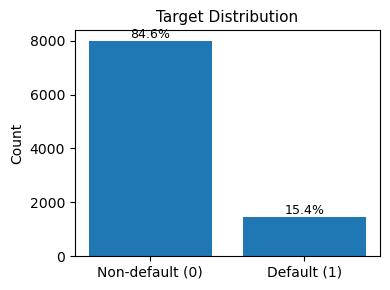

In [252]:
import matplotlib.pyplot as plt

target_counts = df["target_var"].value_counts().sort_index()
target_pct = df["target_var"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(4, 3))
bars = plt.bar(["Non-default (0)", "Default (1)"], target_counts)

for bar, pct in zip(bars, target_pct):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Target Distribution", fontsize=11)
plt.ylabel("Count")
plt.tight_layout()
plt.show()

After removing missing target values, the default class represents around 15.4% of the labelled dataset.

This means the dataset is imbalanced, with default cases forming the minority class.

Therefore, accuracy alone is not suitable. The model will be evaluated using  **ROC-AUC, PR-AUC, recall, precision, F1-score, and confusion matrices**.


### 3.3 Numerical Variables


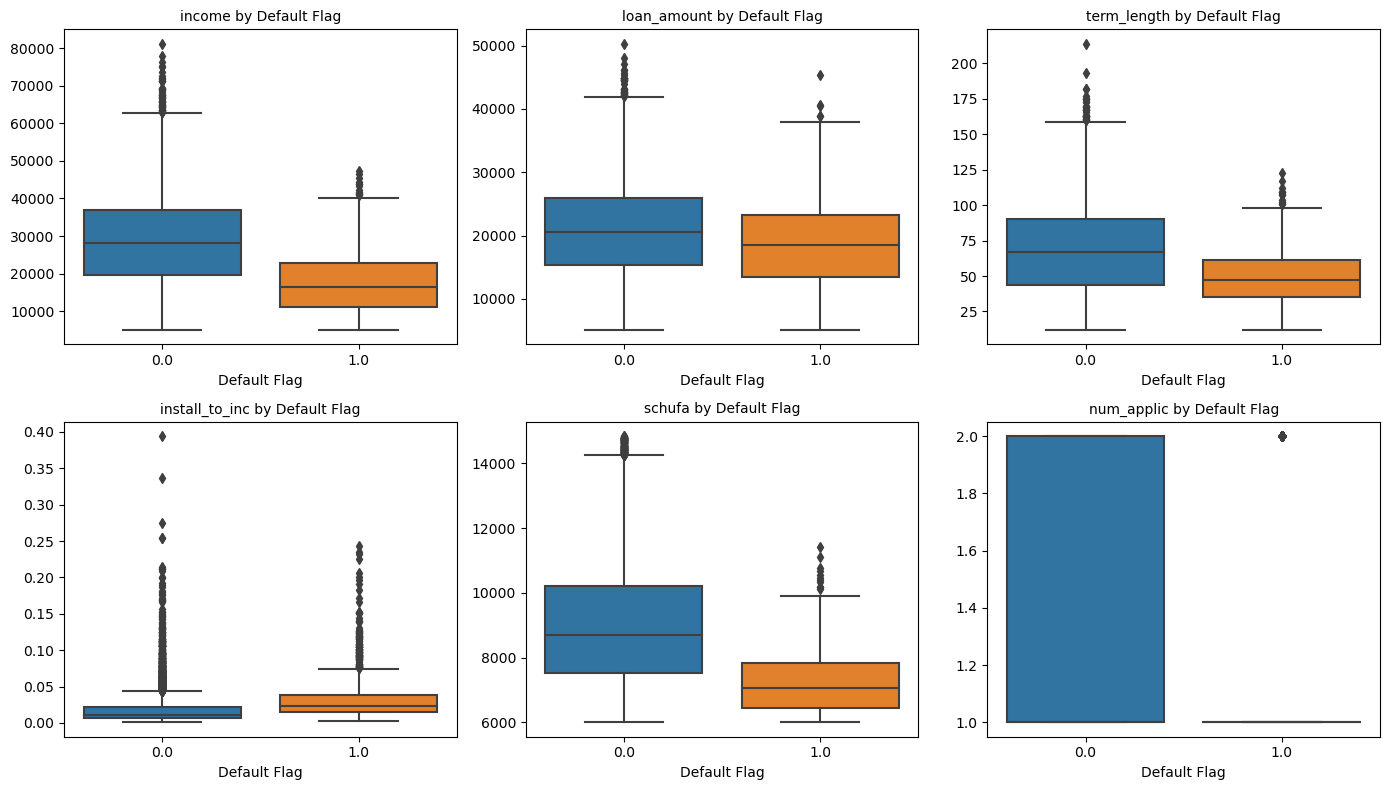

In [253]:
import math
num_cols = ["income", "loan_amount", "term_length", "install_to_inc", "schufa", "num_applic"]
n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x="target_var", y=col, ax=axes[i])
    axes[i].set_title(f"{col} by Default Flag", fontsize=10)
    axes[i].set_xlabel("Default Flag")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The numerical boxplots compare each predictor across non-default and default cases.

Main observations:

- defaulters tend to have lower `income`
- defaulters tend to have lower `schufa` credit scores
- defaulters tend to have higher `install_to_inc`, indicating greater repayment burden
- `income`, `loan_amount`, and `install_to_inc` show skewness and outliers

The strongest candidate risk drivers appear to be `install_to_inc` and `schufa`. Outliers are not automatically removed because extreme values may represent genuine high-risk applicant behaviour. For Logistic Regression, outlier capping is later applied to reduce coefficient distortion.


### 3.4 Categorical Variables


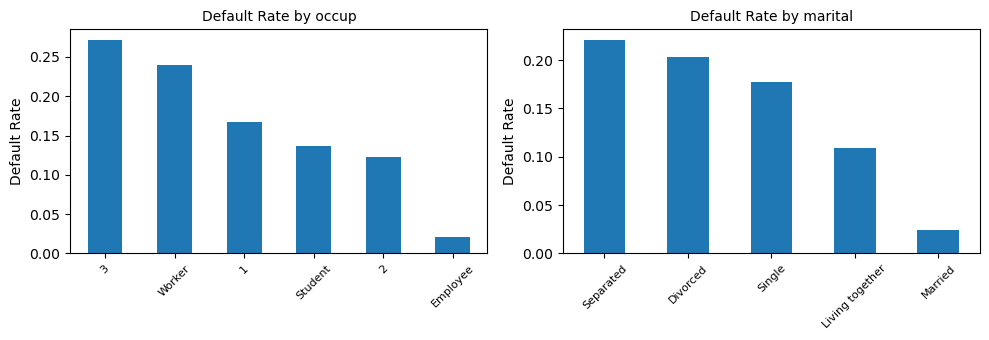

In [257]:
import math
import matplotlib.pyplot as plt
available_cat_cols = [col for col in CATEGORICAL_COLS if col in df.columns]
# Compact default-rate plots for categorical columns
n_cols = len(available_cat_cols)
fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 3.5))

# If only one categorical column, make axes iterable
if n_cols == 1:
    axes = [axes]

for ax, col in zip(axes, available_cat_cols):
    default_rate_by_category = (
        df.groupby(col)[TARGET_COL]
        .agg(["count", "mean"])
        .rename(columns={"mean": "default_rate"})
        .sort_values(by="default_rate", ascending=False)
    )

    default_rate_by_category["default_rate"].head(15).plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"Default Rate by {col}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Default Rate")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.tight_layout()
plt.show()

The categorical default-rate plots show whether default risk differs across groups.

The `occup` column contains mixed formats:

```text
Worker, Employee, Student, 1, 2, 3, NaN
```

The numeric values `1`, `2`, and `3` are retained as separate categories because no data dictionary is provided to map them to named occupations. Missing categorical values are later replaced with `"Unknown"`.

Business caution: categorical default rates should be interpreted carefully where group sizes are small. Marital status may also raise fairness or regulatory considerations in a real credit decisioning setting.


### 3.5 Observation Date


In [161]:
if DATE_COL in df.columns:
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")

    print("\nObservation date range:")
    print("Minimum date:", df[DATE_COL].min())
    print("Maximum date:", df[DATE_COL].max())   


Observation date range:
Minimum date: 2008-01-02 00:00:00
Maximum date: 2018-12-31 00:00:00


The observation dates range from **2008 to 2018**. This allows a time-based train/validation/test split.

A time-based split is more realistic for credit risk than a random split because the model is trained on earlier observations and evaluated on later applicants, closer to how it would be used in practice.


### 3.6 Correlation Analysis


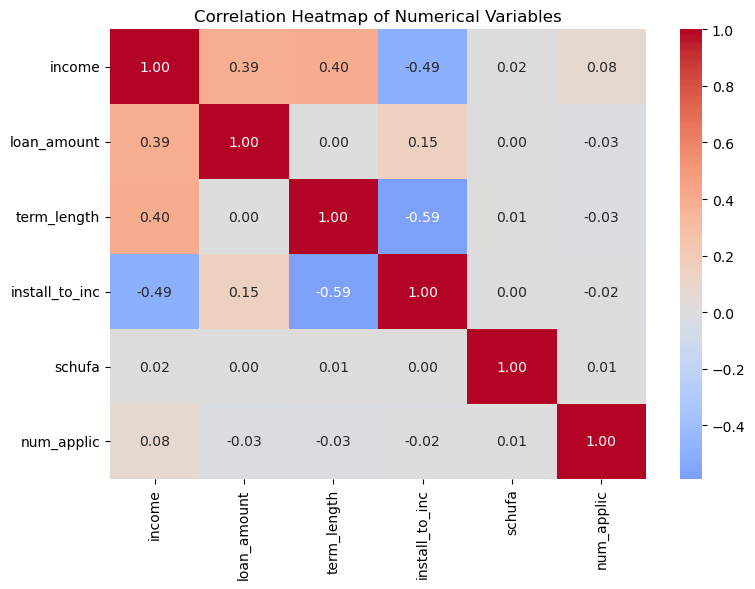

In [166]:
plt.figure(figsize=(8, 6))
corr_matrix = df[available_num_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


The numerical correlation heatmap does not indicate severe multicollinearity. The highest absolute correlation is around **0.59**, below common concern thresholds of **0.8–0.9**.

All numerical variables are therefore retained initially.

The `schufa` score has very low correlation with the other numerical predictors, suggesting it may provide independent credit-risk information rather than duplicating income, loan size, or repayment burden.



## 4. Preprocessing

The preprocessing steps are designed to avoid data leakage.

Any transformation that learns from the data, such as imputation, winsorisation, scaling, or one-hot encoding, is fitted on the training set only and then applied to validation and test sets.

This avoids using information from later observations when preparing the training data.


### 4.1 Target and Date Cleaning


In [260]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Make a copy to avoid modifying the original dataframe
df = df.copy()

# Convert observation date to datetime
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")

# Convert target variable to numeric
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")

# Drop rows with missing target values
df = df.dropna(subset=[TARGET_COL])

# Convert target to integer
df[TARGET_COL] = df[TARGET_COL].astype(int)

# Drop rows with missing observation date
df = df.dropna(subset=[DATE_COL])

print("Shape after dropping missing target and missing observation date:")
print(df.shape)

print("\nTarget distribution after cleaning:")
print(df[TARGET_COL].value_counts(normalize=True))



Shape after dropping missing target and missing observation date:
(8901, 10)

Target distribution after cleaning:
target_var
0    0.846309
1    0.153691
Name: proportion, dtype: float64


Rows with missing `target_var` are removed because the actual default outcome is unknown. Rows with missing or invalid `OBS_DATE` are also removed because a valid observation date is required for the time-based split.

```text
Original rows: 10,000
Rows after target/date cleaning: 8,901
```

The cleaned dataset keeps a similar target distribution, with defaults representing approximately **15.4%** of observations.


### 4.2 Time-Based Split

The data is sorted by `OBS_DATE` and split by time order:

```text
Oldest 70%  → training set
Next 15%    → validation set
Latest 15%  → test set
```

This split tests whether the model generalises to later applicants. After splitting, the default rate is checked in each subset to ensure that each set still contains enough default cases for evaluation.


In [261]:
# Sort by observation date
df = df.sort_values(DATE_COL).reset_index(drop=True)

# 70% train, 15% validation, 15% test by time order
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("\nSplit sizes:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nDefault rate by split:")
print("Train:", train_df[TARGET_COL].mean())
print("Validation:", val_df[TARGET_COL].mean())
print("Test:", test_df[TARGET_COL].mean())


Split sizes:
Train: (6230, 10)
Validation: (1335, 10)
Test: (1336, 10)

Default rate by split:
Train: 0.15168539325842698
Validation: 0.17228464419475656
Test: 0.14446107784431136



The default rate remains usable across all three sets, although the validation set has a slightly higher default rate. We have to note that temporal shifts in default rates may affect model stability.


### 4.3 Missing Value Treatment


In [262]:
# Define feature columns
FEATURE_COLS = NUMERICAL_COLS + CATEGORICAL_COLS

# Convert numerical columns to numeric
for col in NUMERICAL_COLS:
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce")
    val_df[col] = pd.to_numeric(val_df[col], errors="coerce")
    test_df[col] = pd.to_numeric(test_df[col], errors="coerce")

# Convert categorical columns to object type
for col in CATEGORICAL_COLS:
    train_df[col] = train_df[col].astype("object")
    val_df[col] = val_df[col].astype("object")
    test_df[col] = test_df[col].astype("object")

# Separate X and y
X_train = train_df[FEATURE_COLS].copy()
y_train = train_df[TARGET_COL].copy()

X_val = val_df[FEATURE_COLS].copy()
y_val = val_df[TARGET_COL].copy()

X_test = test_df[FEATURE_COLS].copy()
y_test = test_df[TARGET_COL].copy()

print("Missing values before pipeline imputation:")
display(X_train.isna().sum())

Missing values before pipeline imputation:


income            385
loan_amount       390
term_length       362
install_to_inc    376
schufa            382
num_applic        361
occup               0
marital             0
dtype: int64

Numerical missing values are left as `NaN` at this stage and handled inside the preprocessing pipeline using **median imputation**. The imputer is fitted only on the training set, then reused for validation and test sets.

Categorical missing values are handled using an `"Unknown"` category before one-hot encoding. This keeps applicant rows in the dataset and allows the model to learn whether missing category information is associated with risk.


### 4.4 Outlier Treatment


In [263]:
class Winsorizer:
    """
    Learns lower and upper caps from the training data only,
    then applies the same caps to validation/test data.
    Used for Logistic Regression preprocessing.
    """
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        self.lower_bounds_ = None
        self.upper_bounds_ = None

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_bounds_ = X.quantile(self.lower_quantile)
        self.upper_bounds_ = X.quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        X = X.clip(lower=self.lower_bounds_, upper=self.upper_bounds_, axis=1)
        return X.values

For Logistic Regression, numerical variables are capped at the 1st and 99th percentiles using a custom winsoriser.

The caps are learned from the training set only and then applied to validation and test sets. This reduces the influence of extreme values on linear coefficients while retaining the observations.

XGBoost does not use this capping step because tree-based models are less sensitive to extreme numerical values.


### 4.5 Encoding and Scaling


In [264]:
# Logistic Regression numerical pipeline:
# median imputation → winsorisation → standard scaling
numeric_lr_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", Winsorizer(lower_quantile=0.01, upper_quantile=0.99)),
    ("scaler", StandardScaler())
])

# Categorical pipeline:
# missing values → Unknown → one-hot encoding
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Full Logistic Regression preprocessor
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_lr_pipeline, NUMERICAL_COLS),
        ("cat", categorical_pipeline, CATEGORICAL_COLS)
    ],
    remainder="drop"
)

# Fit only on training data
X_train_lr = lr_preprocessor.fit_transform(X_train)

# Apply same transformations to validation and test
X_val_lr = lr_preprocessor.transform(X_val)
X_test_lr = lr_preprocessor.transform(X_test)

print("LR processed shapes:")
print("Train:", X_train_lr.shape)
print("Validation:", X_val_lr.shape)
print("Test:", X_test_lr.shape)

LR processed shapes:
Train: (6230, 19)
Validation: (1335, 19)
Test: (1336, 19)


For Logistic Regression, the preprocessing pipeline applies:

```text
median imputation → winsorisation → standard scaling
```

Categorical variables are imputed with `"Unknown"` and one-hot encoded.

The full pipeline is fitted only on the training data and then applied unchanged to validation and test data.


### 4.6 XGBoost Preprocessing


In [265]:
# XGBoost numerical pipeline:
# median imputation only
numeric_xgb_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Full XGBoost preprocessor
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_xgb_pipeline, NUMERICAL_COLS),
        ("cat", categorical_pipeline, CATEGORICAL_COLS)
    ],
    remainder="drop"
)

# Fit only on training data
X_train_xgb = xgb_preprocessor.fit_transform(X_train)

# Apply same transformations to validation and test
X_val_xgb = xgb_preprocessor.transform(X_val)
X_test_xgb = xgb_preprocessor.transform(X_test)

print("XGBoost processed shapes:")
print("Train:", X_train_xgb.shape)
print("Validation:", X_val_xgb.shape)
print("Test:", X_test_xgb.shape)



XGBoost processed shapes:
Train: (6230, 19)
Validation: (1335, 19)
Test: (1336, 19)


For XGBoost, numerical variables are median-imputed but not scaled. Categorical variables are handled using the same `"Unknown"` imputation and one-hot encoding process.

Scaling is not required for XGBoost because tree-based models split on feature values rather than relying on coefficient magnitudes.


### 4.7 Processed Feature Names


In [266]:
def get_feature_names(preprocessor):
    num_features = NUMERICAL_COLS

    cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
    cat_features = cat_encoder.get_feature_names_out(CATEGORICAL_COLS)

    return list(num_features) + list(cat_features)


lr_feature_names = get_feature_names(lr_preprocessor)
xgb_feature_names = get_feature_names(xgb_preprocessor)

print("Number of LR features:", len(lr_feature_names))
print("Number of XGBoost features:", len(xgb_feature_names))

print("\nFeature names:")
print(lr_feature_names)

Number of LR features: 19
Number of XGBoost features: 19

Feature names:
['income', 'loan_amount', 'term_length', 'install_to_inc', 'schufa', 'num_applic', 'occup_1', 'occup_2', 'occup_3', 'occup_Employee', 'occup_Student', 'occup_Unknown', 'occup_Worker', 'marital_Divorced', 'marital_Living together', 'marital_Married', 'marital_Separated', 'marital_Single', 'marital_Unknown']


After one-hot encoding, both model pipelines produce **19 features**. The expanded feature list is saved so that later model outputs can be interpreted, including Logistic Regression coefficients and XGBoost SHAP values.


### 4.8 Preprocessing Check

In [267]:
print("Missing values after LR preprocessing:")
print(np.isnan(X_train_lr).sum(), np.isnan(X_val_lr).sum(), np.isnan(X_test_lr).sum())

print("Missing values after XGBoost preprocessing:")
print(np.isnan(X_train_xgb).sum(), np.isnan(X_val_xgb).sum(), np.isnan(X_test_xgb).sum())

Missing values after LR preprocessing:
0 0 0
Missing values after XGBoost preprocessing:
0 0 0


The processed Logistic Regression and XGBoost matrices contain **0 missing values** in the train, validation, and test sets. This confirms that the preprocessing pipelines successfully handled missing numerical and categorical inputs after the split.


## 5. Model Selection

Two models are developed and compared:

| Model | Role in the analysis | Business value |
|---|---|---|
| Logistic Regression | Interpretable benchmark | Easy to explain using coefficients; common in credit scoring |
| XGBoost | More flexible machine-learning model | Captures non-linear relationships and feature interactions |

Logistic Regression provides transparency and a useful baseline. XGBoost tests whether a more complex model improves default detection enough to justify reduced interpretability.


## 6. Handling Class Imbalance

Defaults are the minority class, so the models are trained with class-imbalance handling rather than relying on raw accuracy.

| Model | Imbalance treatment |
|---|---|
| Logistic Regression | `class_weight="balanced"` |
| XGBoost | `scale_pos_weight = non_defaults / defaults` |

These settings increase the penalty for misclassifying default cases without changing the original data distribution through upsampling or downsampling.


In [192]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_lr, y_train)



LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [268]:
!pip install xgboost

XGBoost is used as the flexible model because it can capture non-linear relationships and feature interactions. The `scale_pos_weight` parameter is calculated from the training set only and increases the penalty for misclassifying defaulters.


In [193]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

xgb_model.fit(X_train_xgb, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

The initial models are fitted after preprocessing. Hyperparameter tuning is then performed in the next section to select stronger model configurations.


## 7. Hyperparameter Tuning

Hyperparameter tuning is performed using **5-fold stratified cross-validation** on the training set.

The scoring metric is **F1-score**, because the task requires a balance between:

- catching actual defaulters (**recall**)
- avoiding too many false alarms among good customers (**precision**)

The validation and test sets are not used during cross-validation.


In [207]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

### Logistic Regression tuning

In [208]:
# Logistic Regression model
lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42,
    solver="liblinear"
)

# Simple hyperparameter grid
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"]
}

# Stratified CV keeps class ratio in each fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=lr_param_grid,
    scoring="f1",        # prioritise F1 during tuning
    cv=cv,
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_lr, y_train)

best_lr = lr_grid.best_estimator_

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("Best CV F1-score:")
print(lr_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Logistic Regression parameters:
{'C': 10, 'penalty': 'l1'}
Best CV F1-score:
0.6001076438624399


Parameters tested:

- `C`: controls regularisation strength
- `penalty`: L1 or L2 regularisation

Best Logistic Regression result:

```text
C = 10
penalty = l1
CV F1-score = 0.600
```

This is the interpretable baseline used for threshold selection and final evaluation.


### XGBoost tuning


In [209]:
from xgboost import XGBClassifier
# Calculate class imbalance ratio from training set only
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

# Simple grid to keep runtime manageable
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 4],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb,
    param_grid=xgb_param_grid,
    scoring="f1",        # prioritise F1 during tuning
    cv=cv,
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train_xgb, y_train)

best_xgb = xgb_grid.best_estimator_

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

print("Best CV F1-score:")
print(xgb_grid.best_score_)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best XGBoost parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}
Best CV F1-score:
0.6178327498903006


Parameters tested:

- `n_estimators`: number of boosted trees
- `max_depth`: tree complexity
- `learning_rate`: contribution of each tree
- `subsample`: row sampling per tree
- `colsample_bytree`: feature sampling per tree

Best XGBoost result:

```text
n_estimators = 200
max_depth = 4
learning_rate = 0.1
subsample = 0.8
colsample_bytree = 1.0
CV F1-score = 0.618
```

XGBoost achieved a slightly higher cross-validation F1-score than Logistic Regression. The improvement is modest, so final model choice should also consider calibration, interpretability, and business impact.


## 8. Threshold Selection

The default classification threshold of **0.5** is not automatically optimal in credit risk.

The model outputs probabilities. A lower threshold catches more defaulters but also increases the number of good customers flagged as risky. A higher threshold reduces false alarms but may miss more true defaulters.

Thresholds are selected on the validation set using the rule:

```text
Maximise F1-score while keeping recall at least 0.80
```

This reflects a cautious lending objective: detect most defaulters while using F1-score to avoid an overly aggressive decision rule.


In [271]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_score, recall_score, f1_score

def threshold_search(y_true, y_prob, min_recall=0.80):
    rows = []

    for threshold in np.arange(0.01, 1.00, 0.01):
        y_pred = (y_prob >= threshold).astype(int)

        rows.append({
            "threshold": threshold,
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)
        })

    results = pd.DataFrame(rows)

    # Choose threshold: maximise F1 among thresholds with recall >= min_recall
    eligible = results[results["recall"] >= min_recall]

    if len(eligible) > 0:
        best = eligible.sort_values("f1", ascending=False).iloc[0]
    else:
        print(f"No threshold reached recall >= {min_recall}. Using best F1 overall.")
        best = results.sort_values("f1", ascending=False).iloc[0]

    return best, results

In [272]:
# Predicted probabilities on validation set
lr_val_prob = best_lr.predict_proba(X_val_lr)[:, 1]
xgb_val_prob = best_xgb.predict_proba(X_val_xgb)[:, 1]

# Threshold search
best_lr_threshold, lr_threshold_results = threshold_search(
    y_true=y_val,
    y_prob=lr_val_prob,
    min_recall=0.80
)

best_xgb_threshold, xgb_threshold_results = threshold_search(
    y_true=y_val,
    y_prob=xgb_val_prob,
    min_recall=0.80
)

# Save final thresholds
final_lr_threshold = best_lr_threshold["threshold"]
final_xgb_threshold = best_xgb_threshold["threshold"]

print("Best Logistic Regression threshold:")
display(best_lr_threshold)

print("Best XGBoost threshold:")
display(best_xgb_threshold)

Best Logistic Regression threshold:


threshold    0.620000
precision    0.562691
recall       0.800000
f1           0.660682
Name: 61, dtype: float64

Best XGBoost threshold:


threshold    0.440000
precision    0.526455
recall       0.865217
f1           0.654605
Name: 43, dtype: float64

The selected threshold is then fixed and carried forward to the test set. The test set is not used to choose the threshold.


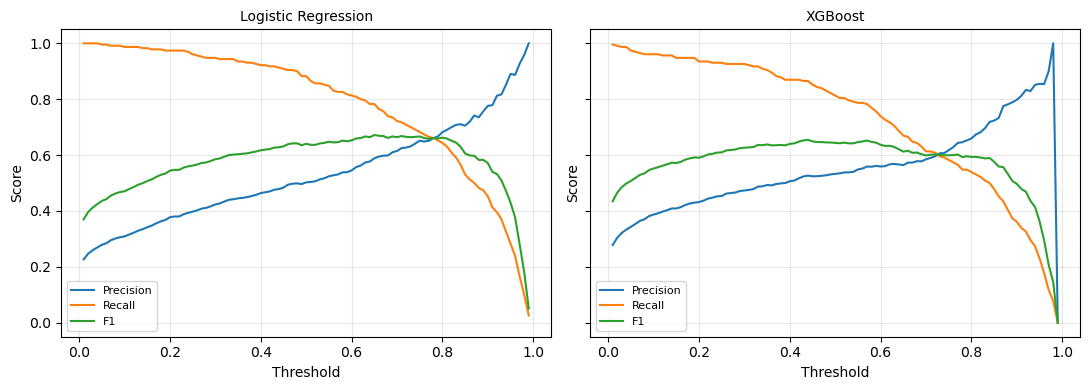

In [273]:
def plot_threshold_comparison(lr_results, xgb_results):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

    model_results = [
        ("Logistic Regression", lr_results),
        ("XGBoost", xgb_results)
    ]

    for ax, (title, results) in zip(axes, model_results):
        ax.plot(results["threshold"], results["precision"], label="Precision")
        ax.plot(results["threshold"], results["recall"], label="Recall")
        ax.plot(results["threshold"], results["f1"], label="F1")

        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Threshold")
        ax.set_ylabel("Score")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

plot_threshold_comparison(lr_threshold_results, xgb_threshold_results)

### Threshold Selection Findings

The threshold selection rule was:

> Maximise F1-score while keeping recall at least 0.80.

| Model | Selected threshold | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.62 | 0.563 | 0.800 | 0.661 |
| XGBoost | 0.44 | 0.526 | 0.865 | 0.655 |

**Logistic Regression** gives the slightly stronger F1-score. At the selected threshold, it catches 80% of actual defaulters and has precision of 56.3%. In business terms, for every 100 applicants flagged as likely defaulters, around 56 would actually default and around 44 would be false positives.

**XGBoost** catches more defaulters, with recall of 86.5%, but has lower precision. For every 100 applicants flagged as likely defaulters, around 53 would actually default and around 47 would be false positives.

The choice depends on the bank’s risk appetite. XGBoost is more conservative because it misses fewer defaulters. Logistic Regression gives a slightly better balance between defaulter detection and false alarms.

A practical business use would be to send flagged applicants for **manual review** rather than automatically rejecting them.


## 9. Model Evaluation

The final uncalibrated models are evaluated on the test set after:

1. preprocessing
2. hyperparameter tuning
3. validation-based threshold selection

| Metric | Business interpretation |
|---|---|
| ROC-AUC | How well the model ranks defaulters above non-defaulters |
| PR-AUC | Ranking quality for the minority default class |
| Recall | Share of actual defaulters detected |
| Precision | Share of flagged applicants who truly default |
| F1-score | Balance between precision and recall |
| Confusion matrix | Counts of good/bad decisions and false alarms |
| Brier score | Quality of probability estimates |


In [274]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix,
    roc_curve, precision_recall_curve
)

def evaluate_model(y_true, y_prob, threshold, model_name):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    }

In [275]:
# Predicted probabilities on test set
lr_test_prob = best_lr.predict_proba(X_test_lr)[:, 1]
xgb_test_prob = best_xgb.predict_proba(X_test_xgb)[:, 1]

# Evaluation
lr_metrics = evaluate_model(
    y_true=y_test,
    y_prob=lr_test_prob,
    threshold=final_lr_threshold,
    model_name="Logistic Regression"
)

xgb_metrics = evaluate_model(
    y_true=y_test,
    y_prob=xgb_test_prob,
    threshold=final_xgb_threshold,
    model_name="XGBoost"
)

results_df = pd.DataFrame([lr_metrics, xgb_metrics])

In [276]:
metrics_table = results_df[[
    "model", "threshold", "accuracy", "precision", "recall",
    "f1", "roc_auc", "pr_auc"
]].copy()

metrics_table = metrics_table.round(3)

display(metrics_table)

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.62,0.859,0.507,0.793,0.618,0.920,0.688
1,XGBoost,0.44,0.823,0.440,0.829,0.575,0.914,0.669


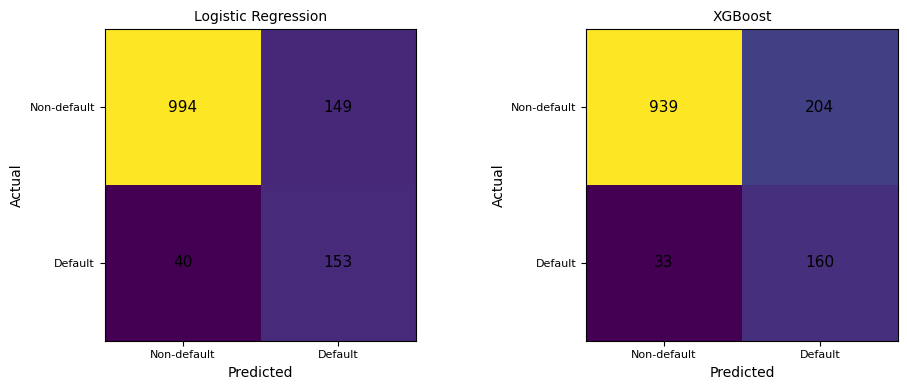

In [277]:
def plot_confusion_matrices(y_test, model_outputs):
    fig, axes = plt.subplots(1, len(model_outputs), figsize=(10, 4))

    if len(model_outputs) == 1:
        axes = [axes]

    for ax, item in zip(axes, model_outputs):
        model_name = item["model_name"]
        y_prob = item["y_prob"]
        threshold = item["threshold"]

        y_pred = (y_prob >= threshold).astype(int)
        cm = confusion_matrix(y_test, y_pred)

        im = ax.imshow(cm)

        ax.set_title(model_name, fontsize=10)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Non-default", "Default"], fontsize=8)
        ax.set_yticklabels(["Non-default", "Default"], fontsize=8)

        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11)

    plt.tight_layout()
    plt.show()


plot_confusion_matrices(
    y_test,
    [
        {
            "model_name": "Logistic Regression",
            "y_prob": lr_test_prob,
            "threshold": final_lr_threshold
        },
        {
            "model_name": "XGBoost",
            "y_prob": xgb_test_prob,
            "threshold": final_xgb_threshold
        }
    ]
)

The confusion matrices translate model performance into business outcomes:

- **False positives** are good customers incorrectly flagged as risky.
- **False negatives** are actual defaulters missed by the model.

XGBoost catches more defaulters, but Logistic Regression creates fewer false positives and has stronger F1 performance on the test set.


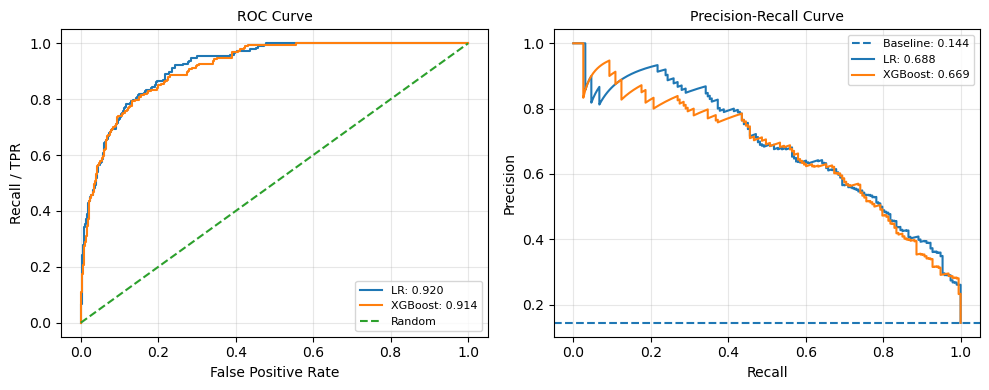

In [281]:
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)
import matplotlib.pyplot as plt

def plot_roc_pr_compact(y_true, prob_dict):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # ROC curve
    ax = axes[0]
    for model_name, y_prob in prob_dict.items():
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc = roc_auc_score(y_true, y_prob)
        ax.plot(fpr, tpr, label=f"{model_name}: {auc:.3f}")

    ax.plot([0, 1], [0, 1], linestyle="--", label="Random")
    ax.set_title("ROC Curve", fontsize=10)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("Recall / TPR")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # Precision-Recall curve
    ax = axes[1]
    baseline = y_true.mean()
    ax.axhline(baseline, linestyle="--", label=f"Baseline: {baseline:.3f}")

    for model_name, y_prob in prob_dict.items():
        precision, recall, _ = precision_recall_curve(y_true, y_prob)
        pr_auc = average_precision_score(y_true, y_prob)
        ax.plot(recall, precision, label=f"{model_name}: {pr_auc:.3f}")

    ax.set_title("Precision-Recall Curve", fontsize=10)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_roc_pr_compact(
    y_test,
    {
        "LR": lr_test_prob,
        "XGBoost": xgb_test_prob
    }
)

The ROC curve compares overall ranking ability, while the Precision-Recall curve is more informative for the minority default class.

Both models perform well above the random baseline. Logistic Regression is slightly stronger on the test set for both ROC-AUC and PR-AUC.


## 10. Calibration

Because the output is a **probability of default**, calibration is important.

A calibrated model means that if a group of applicants receives a predicted default probability of 20%, around 20% of that group should actually default.

Calibration methods used:

| Model | Calibration method | Rationale |
|---|---|---|
| Logistic Regression | Platt Scaling | Suitable sigmoid-style probability adjustment |
| XGBoost | Isotonic Regression | Flexible calibration for tree-based probability outputs |

Calibration is evaluated using:

- **Brier score**: lower is better
- **Calibration curve**: closer to the diagonal line is better


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

In [282]:
# Calibrate Logistic Regression using Platt Scaling
lr_calibrated = CalibratedClassifierCV(
    estimator=best_lr,
    method="sigmoid",
    cv="prefit"
)
lr_calibrated.fit(X_val_lr, y_val)

# Calibrate XGBoost using Isotonic Regression
xgb_calibrated = CalibratedClassifierCV(
    estimator=best_xgb,
    method="isotonic",
    cv="prefit"
)
xgb_calibrated.fit(X_val_xgb, y_val)

# Test probabilities
probs = {
    "LR uncalibrated": best_lr.predict_proba(X_test_lr)[:, 1],
    "LR Platt": lr_calibrated.predict_proba(X_test_lr)[:, 1],
    "XGB uncalibrated": best_xgb.predict_proba(X_test_xgb)[:, 1],
    "XGB Isotonic": xgb_calibrated.predict_proba(X_test_xgb)[:, 1]
}

In [ ]:
calibration_summary = pd.DataFrame([
    {
        "model": name,
        "brier_score": brier_score_loss(y_test, prob),
        "roc_auc": roc_auc_score(y_test, prob),
        "pr_auc": average_precision_score(y_test, prob)
    }
    for name, prob in probs.items()
]).sort_values("brier_score")

display(calibration_summary.round(3))
plt.figure(figsize=(6, 4))

for name, prob in probs.items():
    prob_true, prob_pred = calibration_curve(
        y_test,
        prob,
        n_bins=10,
        strategy="quantile"
    )
    plt.plot(prob_pred, prob_true, marker="o", linewidth=1.5, label=name)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect")
plt.title("Calibration Curve", fontsize=10)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,model,brier_score,roc_auc,pr_auc
1,LR Platt,0.073,0.920,0.688
3,XGB Isotonic,0.078,0.912,0.634
2,XGB uncalibrated,0.110,0.914,0.669
0,LR uncalibrated,0.122,0.920,0.688


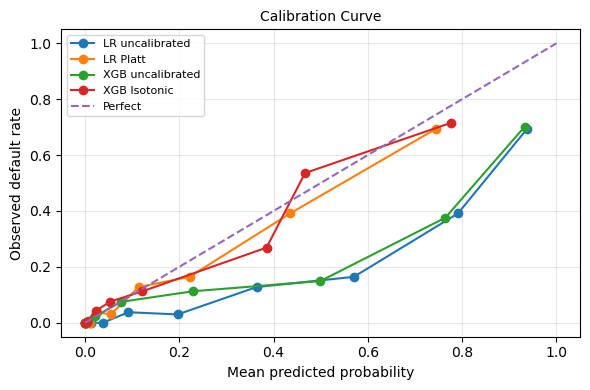

In [ ]:
plt.figure(figsize=(6, 4))

for name, prob in probs.items():
    prob_true, prob_pred = calibration_curve(
        y_test,
        prob,
        n_bins=10,
        strategy="quantile"
    )
    plt.plot(prob_pred, prob_true, marker="o", linewidth=1.5, label=name)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect")
plt.title("Calibration Curve", fontsize=10)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Logistic Regression with Platt Scaling achieved the lowest Brier score (**0.073**), followed by XGBoost with Isotonic Regression (**0.078**). This indicates that calibration improved the probability estimates for both models compared with their uncalibrated versions.

The calibration curve supports this result. The calibrated models are generally closer to the diagonal “perfect calibration” line than the uncalibrated models, especially for Logistic Regression. This suggests that the calibrated probabilities are more reliable for business use, such as risk-based pricing, manual review decisions, and downstream capital management.

In [285]:
def threshold_search(y_true, y_prob, min_recall=0.80):
    rows = []

    for threshold in np.arange(0.01, 1.00, 0.01):
        y_pred = (y_prob >= threshold).astype(int)

        rows.append({
            "threshold": threshold,
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)
        })

    results = pd.DataFrame(rows)
    eligible = results[results["recall"] >= min_recall]

    if len(eligible) > 0:
        return eligible.sort_values("f1", ascending=False).iloc[0]
    else:
        return results.sort_values("f1", ascending=False).iloc[0]

In [286]:
# Validation probabilities after calibration
lr_val_prob_cal = lr_calibrated.predict_proba(X_val_lr)[:, 1]
xgb_val_prob_cal = xgb_calibrated.predict_proba(X_val_xgb)[:, 1]

# Select thresholds
best_lr_cal_threshold = threshold_search(y_val, lr_val_prob_cal, min_recall=0.80)
best_xgb_cal_threshold = threshold_search(y_val, xgb_val_prob_cal, min_recall=0.80)

threshold_table = pd.DataFrame([
    {"model": "LR + Platt", **best_lr_cal_threshold.to_dict()},
    {"model": "XGB + Isotonic", **best_xgb_cal_threshold.to_dict()}
])

display(threshold_table.round(3))

,model,threshold,precision,recall,f1
0,LR + Platt,0.25,0.559,0.800,0.658
1,XGB + Isotonic,0.34,0.528,0.865,0.656


In [287]:
def evaluate_calibrated_model(y_true, y_prob, threshold, model_name):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "model": model_name,
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "brier_score": brier_score_loss(y_true, y_prob),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    }
    
calibrated_results = pd.DataFrame([
    evaluate_calibrated_model(
        y_test,
        probs["LR Platt"],
        best_lr_cal_threshold["threshold"],
        "LR + Platt"
    ),
    evaluate_calibrated_model(
        y_test,
        probs["XGB Isotonic"],
        best_xgb_cal_threshold["threshold"],
        "XGB + Isotonic"
    )
])

display(calibrated_results.round(3))

,model,threshold,precision,recall,f1,roc_auc,pr_auc,brier_score,TP,FP,FN,TN
0,LR + Platt,0.25,0.503,0.793,0.616,0.920,0.688,0.073,153,151,40,992
1,XGB + Isotonic,0.34,0.443,0.829,0.578,0.912,0.634,0.078,160,201,33,942


### Calibration and Final Test Results

After calibration, thresholds are re-selected on the validation set using the same rule:

> Maximise F1-score while keeping recall at least 0.80.

| Model | Validation threshold | Validation precision | Validation recall | Validation F1 |
|---|---:|---:|---:|---:|
| LR + Platt | 0.25 | 0.559 | 0.800 | 0.658 |
| XGB + Isotonic | 0.34 | 0.528 | 0.865 | 0.656 |

Final calibrated test performance:

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC | Brier score |
|---|---:|---:|---:|---:|---:|---:|
| LR + Platt | 0.503 | 0.793 | 0.616 | 0.920 | 0.688 | 0.073 |
| XGB + Isotonic | 0.443 | 0.829 | 0.578 | 0.912 | 0.634 | 0.078 |

The calibrated Logistic Regression model performs better overall on the test set. It has higher precision, F1-score, ROC-AUC, PR-AUC, and a lower Brier score. This means it gives a stronger balance between detecting defaulters, avoiding false positives, and producing reliable probabilities.

The calibrated XGBoost model catches more actual defaulters: **160 out of 193**, compared with **153 out of 193** for Logistic Regression. However, it also incorrectly flags more non-defaulters: **201 false positives**, compared with **151** for Logistic Regression.

Business interpretation: XGBoost is more cautious and reduces missed defaulters, but it sends more good customers for manual review. Logistic Regression misses slightly more defaulters but creates fewer false alarms and has better probability quality.

Based on the combined predictive, calibration, and interpretability considerations, **Logistic Regression with Platt Scaling is the preferred final model** for a balanced credit decisioning workflow. XGBoost remains a useful alternative if the bank prioritises maximum defaulter detection over false-positive control.


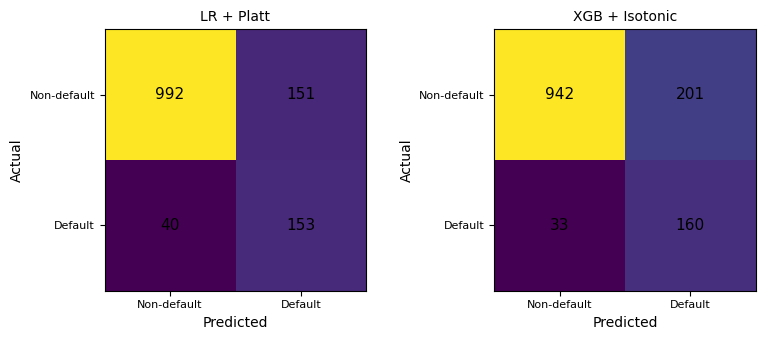

In [288]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

models = [
    ("LR + Platt", probs["LR Platt"], best_lr_cal_threshold["threshold"]),
    ("XGB + Isotonic", probs["XGB Isotonic"], best_xgb_cal_threshold["threshold"])
]

for ax, (name, prob, threshold) in zip(axes, models):
    y_pred = (prob >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred)

    ax.imshow(cm)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Non-default", "Default"], fontsize=8)
    ax.set_yticklabels(["Non-default", "Default"], fontsize=8)

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11)

plt.tight_layout()
plt.show()

The calibrated confusion matrices show the same trade-off in operational terms: XGBoost identifies more actual defaulters, but Logistic Regression produces fewer false positives.

For a real underwriting workflow, the model output should support decision tiers such as approve, reject, or manual review rather than acting as a fully automated rejection tool.


## 11. Explainability

Explainability is important because credit decision models must be understandable to risk teams, business stakeholders, and potentially auditors.

### Logistic Regression

Logistic Regression is explained using coefficients:

```text
Positive coefficient → increases predicted default risk
Negative coefficient → decreases predicted default risk
Larger absolute value → stronger model effect
```

### XGBoost

XGBoost is explained using SHAP values. Mean absolute SHAP values show which features have the largest overall impact on predictions.

The explainability comparison checks whether both models rely on economically sensible risk drivers such as repayment burden, credit score, income, and applicant characteristics.


In [289]:
!pip install shap

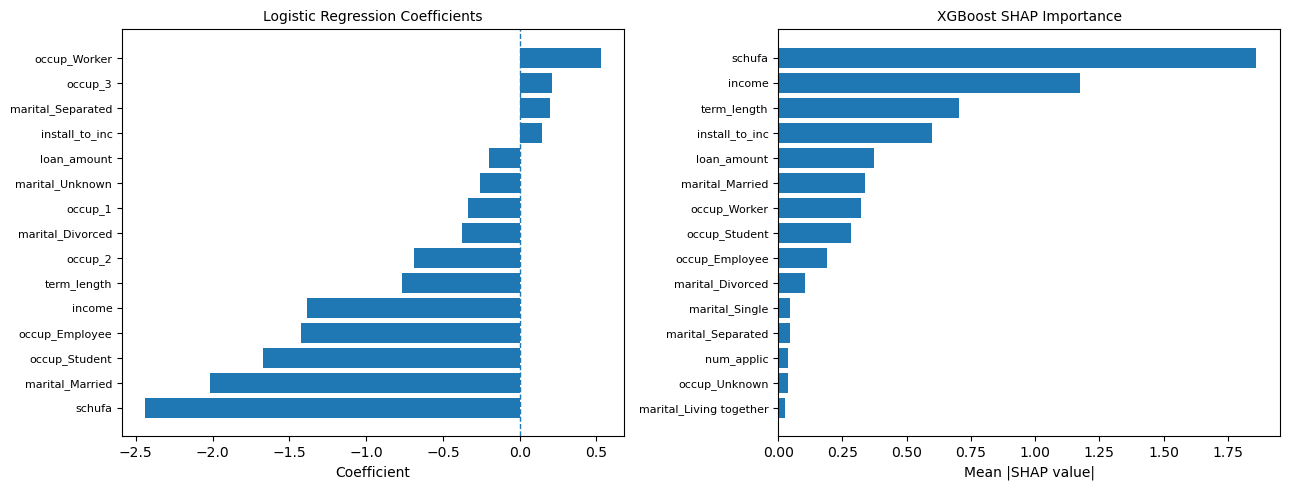

In [291]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

# Logistic Regression coefficients
lr_coef_df = pd.DataFrame({
    "feature": lr_feature_names,
    "coefficient": best_lr.coef_[0]
})

lr_coef_df["importance"] = lr_coef_df["coefficient"].abs()

top_lr = (
    lr_coef_df
    .sort_values("importance", ascending=False)
    .head(15)
    .sort_values("coefficient")
)

# Convert XGBoost processed test data into dataframe
X_test_xgb_df = pd.DataFrame(
    X_test_xgb,
    columns=xgb_feature_names,
    index=X_test.index
)

# SHAP values for XGBoost
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test_xgb_df)

# Mean absolute SHAP value = global feature importance
xgb_shap_df = pd.DataFrame({
    "feature": xgb_feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

top_xgb = (
    xgb_shap_df
    .sort_values("mean_abs_shap", ascending=False)
    .head(15)
    .sort_values("mean_abs_shap")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Logistic Regression coefficients
axes[0].barh(top_lr["feature"], top_lr["coefficient"])
axes[0].axvline(0, linestyle="--", linewidth=1)
axes[0].set_title("Logistic Regression Coefficients", fontsize=10)
axes[0].set_xlabel("Coefficient")
axes[0].tick_params(axis="y", labelsize=8)

# XGBoost SHAP importance
axes[1].barh(top_xgb["feature"], top_xgb["mean_abs_shap"])
axes[1].set_title("XGBoost SHAP Importance", fontsize=10)
axes[1].set_xlabel("Mean |SHAP value|")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()


### Model Explainability Findings

The side-by-side explainability plot compares the most influential variables in each model.

For Logistic Regression, the coefficient direction indicates whether a feature increases or decreases predicted default risk. This makes the model easier to explain to non-technical stakeholders.

For XGBoost, SHAP importance identifies which variables contribute most to predictions in a non-linear model. SHAP is useful because XGBoost can capture interactions that are not visible from simple coefficients.

If variables such as `schufa` and `install_to_inc` appear strongly in the explanations, this supports the EDA finding that creditworthiness and repayment burden are key drivers of mortgage default risk.


## 12. Results Summary

The final calibrated model comparison is:

| Model | Threshold | Precision | Recall | F1 | ROC-AUC | PR-AUC | Brier score |
|---|---:|---:|---:|---:|---:|---:|---:|
| Logistic Regression + Platt Scaling | 0.25 | 0.503 | 0.793 | 0.616 | 0.920 | 0.688 | 0.073 |
| XGBoost + Isotonic Regression | 0.34 | 0.443 | 0.829 | 0.578 | 0.912 | 0.634 | 0.078 |

### Final recommendation

The recommended model is **Logistic Regression with Platt Scaling**.

Reasoning:

- stronger F1-score on the test set
- higher precision, meaning fewer good customers are incorrectly flagged
- higher ROC-AUC and PR-AUC
- lower Brier score, indicating better probability quality
- easier to explain through coefficients

XGBoost detects more defaulters, but the improvement in recall comes with a larger false-positive burden. In a business setting, that means more good customers would be rejected, repriced, or sent for manual review.

## Other Models That Could Be Considered

More sophisticated models could include:

| Model | Why it may help | Limitation |
|---|---|---|
| Random Forest | Captures non-linear patterns and interactions | Less transparent than Logistic Regression |
| LightGBM | Fast gradient boosting model, good for larger datasets | Requires explainability and calibration checks |
| Neural Networks | Can capture complex non-linear relationships | Harder to interpret and justify |


For a production credit-risk setting, model choice should balance predictive performance, interpretability, fairness, calibration, and regulatory requirements.

## Use of Generative AI Tools

Generative AI tools were used as development support, not as a replacement for modelling judgement. They supported:

- refining the pipeline implementation process
- clarifying EDA and preprocessing steps
- debugging Python code
- improving the wording of explanations for business stakeholders

Final decisions on preprocessing, model selection, threshold choice, and interpretation were based on the dataset outputs and credit-risk context.

No raw applicant-level data was shared with public AI tools to follow data privacy, security, and model governance policies.